# Yambda-50M — GPT-2 baseline


## 0. Установка


In [1]:
%pip -q install "pyarrow>=16" "huggingface_hub>=0.27" "tqdm>=4.66"

In [2]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/RecSys_TLab2/Yambda_GPT2')
CHECKPOINT_DIR = PROJECT_DIR / 'checkpoints'
PROTOCOL_DIR = PROJECT_DIR / 'protocol'
METRICS_DIR = PROJECT_DIR / 'metrics'

for path in [CHECKPOINT_DIR, PROTOCOL_DIR, METRICS_DIR]:
    path.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


## 1. Конфигурация


In [3]:
from pathlib import Path
import gc
import json
import math
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

SEED = 666
OUT_DIR = Path('/content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft')  # Поменяй путь, если нужно сохранить в другом месте

# Yambda: timestamps use seconds with five-second quantization
# Числовые значения timestamp заданы в секундах (точность порядка 5 с).
TIMESTAMP_UNIT_SECONDS = 1
GAP_MINUTES = 30
TRAIN_FRACTION = 0.80
VALIDATION_FRACTION = 0.10

SEQ_LEN = 128
D_MODEL = 128
N_LAYERS = 4
N_HEADS = 4
DROPOUT = 0.1
PAD_ID = 0

# Обучение: каждый target из выбранных окон используется ровно раз за проход.
TARGETS_PER_WINDOW = 16          # Несколько next-item targets на одном forward
TRAIN_TARGET_BUDGET = 4_000_000  # None = ВСЕ train-targets за эпоху (долго на T4)
EPOCHS = 4
BATCH_SIZE = 32
GRAD_ACCUM = 1
NUM_WORKERS = 2
LR = 3e-4
MIN_LR_RATIO = 0.1
WARMUP_UPDATES = 300
WEIGHT_DECAY = 0.01
EVAL_EVERY_UPDATES = 4000

# Фиксированный список примеров; одинаков для GPT-2 и будущего RL
VAL_QUERIES_PER_USER = 2
TEST_QUERIES_PER_USER = 4
EVAL_BATCH_SIZE = 32
K = 20

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR.mkdir(parents=True, exist_ok=True)
print('Device:', DEVICE, '| PyTorch:', torch.__version__)
print('Results:', OUT_DIR)

Device: cuda | PyTorch: 2.11.0+cu130
Results: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft


## 2. Загрузка данных


In [4]:
from huggingface_hub import hf_hub_download
import pyarrow.parquet as pq

PARQUET_PATH = hf_hub_download(
    repo_id='yandex/yambda',
    repo_type='dataset',
    filename='sequential/50m/listens.parquet'
)
print('Parquet:', PARQUET_PATH)

def arrow_values(table, name):
    return table[name].combine_chunks().to_numpy(zero_copy_only=False)

def arrow_list(table, name):
    arr = table[name].combine_chunks()
    values = arr.values
    if values.null_count:
        values = values.fill_null(0)
    return arr.offsets.to_numpy(zero_copy_only=False), values.to_numpy(zero_copy_only=False)

parquet = pq.read_table(PARQUET_PATH, columns=[
    'uid', 'item_id', 'timestamp', 'is_organic', 'played_ratio_pct'
])
user_ids = arrow_values(parquet, 'uid').astype(np.uint32, copy=False)
offsets, raw_items = arrow_list(parquet, 'item_id')
o_time, timestamp_seconds = arrow_list(parquet, 'timestamp')
o_organic, organic = arrow_list(parquet, 'is_organic')
o_ratio, played_ratio = arrow_list(parquet, 'played_ratio_pct')

if not (np.array_equal(offsets, o_time) and np.array_equal(offsets, o_organic)
        and np.array_equal(offsets, o_ratio)):
    raise ValueError('Parquet: несовпадающие offsets списковых колонок')

offsets = offsets.astype(np.int64, copy=False)
raw_items = raw_items.astype(np.uint32, copy=False)
timestamp_seconds = timestamp_seconds.astype(np.uint32, copy=False)
organic = organic.astype(np.uint8, copy=False)
played_ratio = played_ratio.astype(np.uint16, copy=False)
del parquet, o_time, o_organic, o_ratio
gc.collect()

print(f'Users: {len(user_ids):,}; listens: {len(raw_items):,}')
print(f'Timestamp values: [{timestamp_seconds.min()}, {timestamp_seconds.max()}], 1 timestamp unit = {TIMESTAMP_UNIT_SECONDS} sec')

sequential/50m/listens.parquet: reconstructing file:   0%|          |  0.00B /  426MB            

sequential/50m/listens.parquet: downloading bytes:           |  0.00B            

Parquet: /root/.cache/huggingface/hub/datasets--yandex--yambda/snapshots/dd6f3a19eef5866e346c3270e098baa641a44948/sequential/50m/listens.parquet
Users: 9,238; listens: 46,467,212
Timestamp values: [0, 26000000], 1 timestamp unit = 1 sec


## 3. Временное разбиение и каталог


In [5]:
# Между сплитами 30 минут. timestamp хранит время в секундах, с квантизацией до 5 секунд.
GAP_SECONDS = GAP_MINUTES * 60
T_VAL, T_TEST = [int(v) for v in np.quantile(timestamp_seconds, [
    TRAIN_FRACTION, TRAIN_FRACTION + VALIDATION_FRACTION
])]
VAL_START = T_VAL + GAP_SECONDS
TEST_START = T_TEST + GAP_SECONDS

train_start = offsets[:-1].copy()
train_end = np.empty(len(user_ids), dtype=np.int64)
val_start = np.empty(len(user_ids), dtype=np.int64)
val_end = np.empty(len(user_ids), dtype=np.int64)
test_start = np.empty(len(user_ids), dtype=np.int64)
test_end = offsets[1:].copy()

for u in tqdm(range(len(user_ids)), desc='Temporal split'):
    a, b = int(offsets[u]), int(offsets[u + 1])
    ts = timestamp_seconds[a:b]
    train_end[u] = a + np.searchsorted(ts, T_VAL, side='left')
    val_start[u] = a + np.searchsorted(ts, VAL_START, side='left')
    val_end[u] = a + np.searchsorted(ts, T_TEST, side='left')
    test_start[u] = a + np.searchsorted(ts, TEST_START, side='left')

train_mask = timestamp_seconds < T_VAL
val_mask = (timestamp_seconds >= VAL_START) & (timestamp_seconds < T_TEST)
test_mask = timestamp_seconds >= TEST_START
embargo_mask = ~(train_mask | val_mask | test_mask)

# Не ограничиваем каталог: все треки, встречающиеся в Yambda-50M.
raw_catalog = np.unique(raw_items)
vocab_size = len(raw_catalog) + 1        # 0 только PAD
tokens = np.searchsorted(raw_catalog, raw_items).astype(np.int32) + 1
train_counts = np.bincount(tokens[train_mask], minlength=vocab_size).astype(np.int64)

split_counts = {k: int(m.sum()) for k, m in {
    'train': train_mask, 'validation': val_mask, 'test': test_mask, 'embargo': embargo_mask
}.items()}
print('Split:', split_counts)
print('Catalog:', vocab_size - 1, '| Train-warm:', int(np.count_nonzero(train_counts[1:])))
print('Boundaries (seconds):', T_VAL, T_TEST, '| 30-min gap =', GAP_SECONDS, 'seconds')
print('Gap in real minutes:', GAP_SECONDS / 60)

# Контроль границ без assert: реальные события разных сплитов не попадают в один интервал.
for split_name, mask, low, high in [
    ('train', train_mask, None, T_VAL),
    ('validation', val_mask, VAL_START, T_TEST),
    ('test', test_mask, TEST_START, None)
]:
    ts = timestamp_seconds[mask]
    print(split_name, '| min/max timestamp (seconds):', (int(ts.min()), int(ts.max())) if len(ts) else None,
          '| count:', len(ts))
    if not len(ts) or (low is not None and ts.min() < low) or (high is not None and ts.max() >= high):
        raise ValueError(f'Invalid temporal split: {split_name}')

del train_mask, val_mask, test_mask, embargo_mask
# Достаточно хранить границы и координаты событий; создадим маски при необходимости.
gc.collect()

Temporal split:   0%|          | 0/9238 [00:00<?, ?it/s]

Split: {'train': 37173766, 'validation': 4645316, 'test': 4640751, 'embargo': 7379}
Catalog: 877168 | Train-warm: 775693
Boundaries (seconds): 22115765 24126675 | 30-min gap = 1800 seconds
Gap in real minutes: 30.0
train | min/max timestamp (seconds): (0, 22115760) | count: 37173766
validation | min/max timestamp (seconds): (22117565, 24126670) | count: 4645316
test | min/max timestamp (seconds): (24128475, 26000000) | count: 4640751


18

## 4. Обучающие окна


In [6]:
# Окна задаются тройками (user_idx, first_target_idx, end_target_idx).
# Интервалы target индексов [first, end) не пересекаются.
window_users = []
window_first = []
window_end = []

for u in tqdm(range(len(user_ids)), desc='Build next-item windows'):
    first_target = int(train_start[u]) + 1
    stop = int(train_end[u])
    starts = np.arange(first_target, stop, TARGETS_PER_WINDOW, dtype=np.int64)
    if len(starts):
        window_users.append(np.full(len(starts), u, dtype=np.int32))
        window_first.append(starts)
        window_end.append(np.minimum(starts + TARGETS_PER_WINDOW, stop))

window_users = np.concatenate(window_users)
window_first = np.concatenate(window_first)
window_end = np.concatenate(window_end)
all_train_targets = int(np.maximum(train_end - train_start - 1, 0).sum())

rng = np.random.default_rng(SEED)
all_window_indices = np.arange(len(window_users), dtype=np.int64)
if TRAIN_TARGET_BUDGET is None or TRAIN_TARGET_BUDGET >= all_train_targets:
    selected_window_indices = all_window_indices
else:
    estimated_windows = min(len(all_window_indices), math.ceil(
        TRAIN_TARGET_BUDGET / TARGETS_PER_WINDOW))
    selected_window_indices = rng.choice(all_window_indices, size=estimated_windows, replace=False)

seen_train_targets = int((window_end[selected_window_indices] - window_first[selected_window_indices]).sum())
print(f'Available train targets: {all_train_targets:,}')
print(f'Selected targets per epoch: {seen_train_targets:,} ({seen_train_targets / all_train_targets:.1%})')
print(f'Windows per epoch: {len(selected_window_indices):,}')

class WindowDataset(Dataset):
    def __init__(self, indices):
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, row):
        j = int(self.indices[row])
        u = int(window_users[j])
        first, stop = int(window_first[j]), int(window_end[j])
        a = int(train_start[u])
        left = max(a, stop - 1 - SEQ_LEN)
        context = tokens[left:stop - 1]
        n_targets = stop - first
        x = np.zeros(SEQ_LEN, dtype=np.int64)
        target_positions = np.zeros(TARGETS_PER_WINDOW, dtype=np.int64)
        target_ids = np.zeros(TARGETS_PER_WINDOW, dtype=np.int64)
        x[:len(context)] = context
        target_positions[:n_targets] = np.arange(first - 1 - left, stop - 1 - left)
        target_ids[:n_targets] = tokens[first:stop]
        return (torch.from_numpy(x), torch.from_numpy(target_positions),
                torch.from_numpy(target_ids), torch.tensor(n_targets))

train_loader = DataLoader(
    WindowDataset(selected_window_indices), batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == 'cuda'),
    persistent_workers=(NUM_WORKERS > 0)
)

Build next-item windows:   0%|          | 0/9238 [00:00<?, ?it/s]

Available train targets: 37,165,097
Selected targets per epoch: 3,993,272 (10.7%)
Windows per epoch: 250,000


## 5. Validation и test


In [7]:
def fixed_queries(lefts, rights, per_user, seed):
    rng = np.random.default_rng(seed)
    chosen = []
    for u in range(len(user_ids)):
        lo = int(lefts[u]) + 1
        hi = int(rights[u])
        n = min(per_user, max(0, hi - lo))
        if n:
            positions = rng.choice(np.arange(lo, hi, dtype=np.int64), size=n, replace=False)
            chosen.extend((u, int(p)) for p in sorted(positions))
    return np.asarray(chosen, dtype=np.int64).reshape(-1, 2)

val_queries = fixed_queries(val_start, val_end, VAL_QUERIES_PER_USER, SEED + 10)
test_queries = fixed_queries(test_start, test_end, TEST_QUERIES_PER_USER, SEED + 20)
print('Val queries:', len(val_queries), '| Test queries:', len(test_queries))

np.savez_compressed(OUT_DIR / 'rl_protocol.npz',
    raw_catalog=raw_catalog, user_ids=user_ids,
    offsets=offsets, train_start=train_start, train_end=train_end,
    val_start=val_start, val_end=val_end,
    test_start=test_start, test_end=test_end,
    val_queries=val_queries, test_queries=test_queries,
    train_counts=train_counts,
    selected_window_indices=selected_window_indices,
    window_users=window_users, window_first=window_first, window_end=window_end,
    t_val=np.int64(T_VAL), t_test=np.int64(T_TEST),
    gap_seconds=np.int64(GAP_SECONDS), timestamp_unit_seconds=np.int64(TIMESTAMP_UNIT_SECONDS),
)
protocol = {
    'dataset': 'yandex/yambda/sequential/50m/listens.parquet',
    'timestamp_unit_seconds': TIMESTAMP_UNIT_SECONDS,
    'split': {'train_end_second_exclusive': T_VAL, 'val_start_second_inclusive': VAL_START,
              'val_end_second_exclusive': T_TEST, 'test_start_second_inclusive': TEST_START,
              'gap_minutes': GAP_MINUTES, 'gap_seconds': GAP_SECONDS},
    'catalog_policy': 'transductive_all_IDs; popularity computed from train only',
    'context_policy': 'strict_same_split_past_only; embargo_excluded; rolling_real_events',
    'metrics': 'full_catalog_exact_topk; one heldout next item per query',
    'val_queries': len(val_queries), 'test_queries': len(test_queries),
    'sample_seed': SEED,
    'all_train_targets': all_train_targets,
    'selected_targets_per_epoch': seen_train_targets,
    'source_revision': PARQUET_PATH.split('/snapshots/')[1].split('/')[0]
        if '/snapshots/' in PARQUET_PATH else 'unavailable',
}
(OUT_DIR / 'protocol.json').write_text(json.dumps(protocol, indent=2, ensure_ascii=False))
print('Saved fixed queries and protocol:', OUT_DIR)

Val queries: 16379 | Test queries: 35848
Saved fixed queries and protocol: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft


## 6. Архитектура модели


In [8]:
class DecoderBlock(nn.Module):
    def __init__(self, width, heads, dropout):
        super().__init__()
        self.heads = heads
        self.head_dim = width // heads
        self.ln1 = nn.LayerNorm(width)
        self.qkv = nn.Linear(width, 3 * width)
        self.attn_out = nn.Linear(width, width)
        self.ln2 = nn.LayerNorm(width)
        self.fc1 = nn.Linear(width, 4 * width)
        self.fc2 = nn.Linear(4 * width, width)
        self.drop = nn.Dropout(dropout)
        self.attn_dropout = dropout

    def forward(self, x):
        batch, length, width = x.shape
        q, k, v = self.qkv(self.ln1(x)).chunk(3, dim=-1)
        q = q.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)
        k = k.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)
        v = v.reshape(batch, length, self.heads, self.head_dim).transpose(1, 2)
        z = F.scaled_dot_product_attention(
            q, k, v, is_causal=True,
            dropout_p=self.attn_dropout if self.training else 0.0
        )
        z = z.transpose(1, 2).contiguous().reshape(batch, length, width)
        x = x + self.drop(self.attn_out(z))
        return x + self.drop(self.fc2(F.gelu(self.fc1(self.ln2(x)), approximate='tanh')))

class GPT2Rec(nn.Module):
    def __init__(self, n_items, context_len, width, layers, heads, dropout):
        super().__init__()
        self.item_embedding = nn.Embedding(n_items, width, padding_idx=PAD_ID)
        self.position_embedding = nn.Embedding(context_len, width)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([DecoderBlock(width, heads, dropout) for _ in range(layers)])
        self.final_ln = nn.LayerNorm(width)
        self.apply(self._initialize)
        with torch.no_grad():
            self.item_embedding.weight[PAD_ID].zero_()

    @staticmethod
    def _initialize(module):
        if isinstance(module, (nn.Embedding, nn.Linear)):
            nn.init.normal_(module.weight, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def encode(self, ids):
        time_positions = torch.arange(ids.shape[1], device=ids.device)
        h = self.drop(self.item_embedding(ids) + self.position_embedding(time_positions))
        for block in self.blocks:
            h = block(h)
        return self.final_ln(h)

    def scores(self, selected_states):
        # Тот же item embedding используется как выходной классификатор.
        # Класс 0 = PAD, он не является кандидатом на рекомендацию.
        return F.linear(selected_states, self.item_embedding.weight[1:])

model = GPT2Rec(vocab_size, SEQ_LEN, D_MODEL, N_LAYERS, N_HEADS, DROPOUT).to(DEVICE)
print('Total parameters:', f'{sum(p.numel() for p in model.parameters()):,}')
print('Candidates in softmax:', vocab_size - 1)

Total parameters: 113,087,360
Candidates in softmax: 877168


## 7. Метрики


In [9]:
def query_batch(queries, starts):
    x = torch.zeros((len(queries), SEQ_LEN), dtype=torch.long)
    lengths = torch.empty(len(queries), dtype=torch.long)
    true_items = np.empty(len(queries), dtype=np.int64)
    last_items = np.empty(len(queries), dtype=np.int64)
    repeats = np.empty(len(queries), dtype=bool)

    for row, (u, p) in enumerate(queries):
        p = int(p)
        a = max(int(starts[int(u)]), p - SEQ_LEN)
        context = tokens[a:p]
        x[row, :len(context)] = torch.from_numpy(context.astype(np.int64, copy=False))
        lengths[row] = len(context)
        true_items[row] = int(tokens[p])
        last_items[row] = int(context[-1])
        repeats[row] = np.any(context == true_items[row])
    return x, lengths, true_items, last_items, repeats


def hit_metrics(predictions, targets):
    if len(targets) == 0:
        return {'n': 0, 'recall@20': None, 'ndcg@20': None, 'mrr@20': None}
    matches = predictions == targets[:, None]
    ranks = np.where(matches.any(axis=1), matches.argmax(axis=1) + 1, 0)
    good = ranks > 0
    return {
        'n': int(len(targets)),
        'recall@20': float(good.mean()),
        'ndcg@20': float(np.mean(np.where(good, 1 / np.log2(np.maximum(ranks, 1) + 1), 0))),
        'mrr@20': float(np.mean(np.where(good, 1 / np.maximum(ranks, 1), 0))),
    }


def analyze_predictions(preds, truth, organic_labels, ratio_labels, repeated, last_items, recommendation_repeat):
    warm = train_counts[truth] > 0
    positive = ratio_labels > 50
    valid = np.ones(len(truth), dtype=bool)
    slices = {
        'all': valid,
        'positive_listen_gt50': positive,
        'low_completion_le50': ~positive,
        'recommendation_driven': organic_labels == 0,
        'organic': organic_labels == 1,
        'warm': warm,
        'cold': ~warm,
        'repeated_in_context': repeated,
        'not_in_context': ~repeated,
    }
    result = {name: hit_metrics(preds[mask], truth[mask]) for name, mask in slices.items()}
    result['behavior'] = {
        'unique_top20_items': int(np.unique(preds).size),
        'catalog_coverage@20': float(np.unique(preds).size / (vocab_size - 1)),
        'top1_max_share': float(np.unique(preds[:, 0], return_counts=True)[1].max() / len(preds)),
        'top20_repeat_from_recent_history': float(recommendation_repeat.mean()),
        'top1_repeat_from_recent_history': float(recommendation_repeat[:, 0].mean()),
        'avg_train_popularity_top1': float(train_counts[preds[:, 0]].mean()),
        'top1_equals_last_item': float((preds[:, 0] == last_items).mean()),
    }
    return result


@torch.inference_mode()
def evaluate(policy, queries, split_starts, keep_predictions=False):
    policy.eval()
    pred_parts, true_parts, last_parts, repeat_parts = [], [], [], []
    organic_parts, ratio_parts, recommended_repeat_parts = [], [], []
    for lo in tqdm(range(0, len(queries), EVAL_BATCH_SIZE), desc='Full-catalog eval', leave=False):
        q = queries[lo:lo + EVAL_BATCH_SIZE]
        x, lengths, truth, last, repeats = query_batch(q, split_starts)
        x = x.to(DEVICE, non_blocking=True)
        lengths = lengths.to(DEVICE, non_blocking=True)
        with torch.autocast('cuda', dtype=torch.float16, enabled=(DEVICE.type == 'cuda')):
            states = policy.encode(x)
            last_state = states[torch.arange(len(q), device=DEVICE), lengths - 1]
            scores = policy.scores(last_state)
        # Exactly K candidates out of the full (non-PAD) catalog, token IDs are 1-based.
        topk = scores.topk(K, dim=-1).indices.add(1).cpu().numpy()
        recommended_repeat_parts.append(
            (topk[:, :, None] == x.cpu().numpy()[:, None, :]).any(axis=-1))
        pred_parts.append(topk)
        true_parts.append(truth)
        last_parts.append(last)
        repeat_parts.append(repeats)
        positions = q[:, 1]
        organic_parts.append(organic[positions])
        ratio_parts.append(played_ratio[positions])
    preds = np.concatenate(pred_parts)
    targets = np.concatenate(true_parts)
    last = np.concatenate(last_parts)
    repeated = np.concatenate(repeat_parts)
    result = analyze_predictions(preds, targets, np.concatenate(organic_parts),
                                 np.concatenate(ratio_parts), repeated, last,
                                 np.concatenate(recommended_repeat_parts))
    if keep_predictions:
        return result, {'top20': preds, 'targets': targets, 'last': last, 'repeats': repeated,
                        'organic': np.concatenate(organic_parts), 'played_ratio_pct': np.concatenate(ratio_parts)}
    return result


def popularity_baseline(queries, split_starts):
    top = np.argsort(-train_counts[1:], kind='stable')[:K].astype(np.int64) + 1
    preds = np.tile(top, (len(queries), 1))
    truth = tokens[queries[:, 1]]
    return hit_metrics(preds, truth)

print('Popularity VAL:', popularity_baseline(val_queries, val_start))
print('Last-item-only VAL Recall@1:', float(np.mean([
    tokens[p - 1] == tokens[p] for _, p in val_queries
])))

Popularity VAL: {'n': 16379, 'recall@20': 0.018987728188534097, 'ndcg@20': 0.00681098922580654, 'mrr@20': 0.0034919858309985213}
Last-item-only VAL Recall@1: 0.03333536845961292


## 8. Обучение


In [10]:
steps_per_epoch = len(train_loader)
updates_per_epoch = math.ceil(steps_per_epoch / GRAD_ACCUM)
total_updates = EPOCHS * updates_per_epoch

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def lr_multiplier(update):
    if update < WARMUP_UPDATES:
        return max(1e-3, (update + 1) / max(1, WARMUP_UPDATES))
    progress = (update - WARMUP_UPDATES) / max(1, total_updates - WARMUP_UPDATES)
    return MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * min(1., progress)))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_multiplier)
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

best_ndcg = -1.0
history = []
update_step = 0
processed_targets = 0
optimizer.zero_grad(set_to_none=True)

for epoch in range(EPOCHS):
    model.train()
    running_loss_sum = 0.0
    loss_target_count = 0
    progress = tqdm(train_loader, desc=f'GPT-2 epoch {epoch + 1}/{EPOCHS}')
    for batch_idx, (x, positions, labels, lengths) in enumerate(progress, start=1):
        x = x.to(DEVICE, non_blocking=True)
        positions = positions.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        lengths = lengths.to(DEVICE, non_blocking=True)

        rows = torch.arange(len(x), device=DEVICE).unsqueeze(1)
        mask = torch.arange(TARGETS_PER_WINDOW, device=DEVICE).unsqueeze(0) < lengths.unsqueeze(1)
        with torch.autocast('cuda', dtype=torch.float16, enabled=(DEVICE.type == 'cuda')):
            hidden = model.encode(x)
            relevant_states = hidden[rows.expand_as(positions)[mask], positions[mask]]
            logits = model.scores(relevant_states)
            loss = F.cross_entropy(logits.float(), labels[mask] - 1)

        if not torch.isfinite(loss):
            raise FloatingPointError(f'Non-finite training loss: epoch={epoch + 1}, batch={batch_idx}')
        scaler.scale(loss / GRAD_ACCUM).backward()
        current_n = int(lengths.sum().item())
        running_loss_sum += loss.item() * current_n
        loss_target_count += current_n
        processed_targets += current_n
        do_update = (batch_idx % GRAD_ACCUM == 0) or (batch_idx == steps_per_epoch)
        del logits, hidden, relevant_states, loss

        if do_update:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            update_step += 1

            if update_step % 50 == 0:
                progress.set_postfix(loss=f'{running_loss_sum / loss_target_count:.3f}',
                                     targets=f'{processed_targets / 1e6:.2f}M',
                                     lr=f'{scheduler.get_last_lr()[0]:.2e}')

            if update_step % EVAL_EVERY_UPDATES == 0 or (epoch == EPOCHS - 1 and batch_idx == steps_per_epoch):
                val_result = evaluate(model, val_queries, val_start)
                current_ndcg = val_result['all']['ndcg@20']
                record = {
                    'epoch': epoch + 1, 'optimizer_update': update_step,
                    'seen_targets': processed_targets,
                    'train_cross_entropy': running_loss_sum / loss_target_count,
                    'val_ndcg@20': current_ndcg,
                    'val_recall@20': val_result['all']['recall@20'],
                    'val_positive_ndcg@20': val_result['positive_listen_gt50']['ndcg@20'],
                    'val_warm_ndcg@20': val_result['warm']['ndcg@20'],
                }
                history.append(record)
                print('Evaluation:', record)
                if current_ndcg > best_ndcg:
                    best_ndcg = current_ndcg
                    torch.save({
                        'model': model.state_dict(),
                        'vocab_size': vocab_size,
                        'model_config': {'seq_len': SEQ_LEN, 'd_model': D_MODEL,
                                         'n_layers': N_LAYERS, 'n_heads': N_HEADS,
                                         'dropout': DROPOUT},
                        'best_val_ndcg@20': best_ndcg,
                        'optimizer_update': update_step,
                        'seen_targets': processed_targets,
                    }, OUT_DIR / 'best_gpt2.pt')
                    print('Best checkpoint updated:', OUT_DIR / 'best_gpt2.pt')
                (OUT_DIR / 'training_history.json').write_text(json.dumps(history, indent=2))
                model.train()

print('Total targets processed (all epochs):', f'{processed_targets:,}')
print('Best validation NDCG@20:', best_ndcg)

GPT-2 epoch 1/4:   0%|          | 0/7813 [00:00<?, ?it/s]

Full-catalog eval:   0%|          | 0/512 [00:00<?, ?it/s]

Evaluation: {'epoch': 1, 'optimizer_update': 4000, 'seen_targets': 2044649, 'train_cross_entropy': 10.795411172246087, 'val_ndcg@20': 0.011932701116516937, 'val_recall@20': 0.030404786617009585, 'val_positive_ndcg@20': 0.01247405872186141, 'val_warm_ndcg@20': 0.012714397058771204}
Best checkpoint updated: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft/best_gpt2.pt


GPT-2 epoch 2/4:   0%|          | 0/7813 [00:00<?, ?it/s]

Full-catalog eval:   0%|          | 0/512 [00:00<?, ?it/s]

...

Evaluation: {'epoch': 4, 'optimizer_update': 24000, 'seen_targets': 12266579, 'train_cross_entropy': 8.15346243523647, 'val_ndcg@20': 0.04400075250254494, 'val_recall@20': 0.09866292203431223, 'val_positive_ndcg@20': 0.045550375185254885, 'val_warm_ndcg@20': 0.046883185352536015}
Best checkpoint updated: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft/best_gpt2.pt


Full-catalog eval:   0%|          | 0/512 [00:00<?, ?it/s]

Evaluation: {'epoch': 4, 'optimizer_update': 28000, 'seen_targets': 14311063, 'train_cross_entropy': 8.172260771772178, 'val_ndcg@20': 0.04546250589103753, 'val_recall@20': 0.10153245008852799, 'val_positive_ndcg@20': 0.047124883740853656, 'val_warm_ndcg@20': 0.04844069633029558}
Best checkpoint updated: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft/best_gpt2.pt


Full-catalog eval:   0%|          | 0/512 [00:00<?, ?it/s]

Evaluation: {'epoch': 4, 'optimizer_update': 31252, 'seen_targets': 15973088, 'train_cross_entropy': 8.180945125946721, 'val_ndcg@20': 0.04681547901853438, 'val_recall@20': 0.10336406374015508, 'val_positive_ndcg@20': 0.04823237182817487, 'val_warm_ndcg@20': 0.04988230099171056}
Best checkpoint updated: /content/drive/MyDrive/RecSys_TLab/Yambda_GPT2/sft/best_gpt2.pt
Total targets processed (all epochs): 15,973,088
Best validation NDCG@20: 0.04681547901853438


## 9. Тестирование


In [11]:
checkpoint = torch.load(OUT_DIR / 'best_gpt2.pt', map_location='cpu', weights_only=True)
model.load_state_dict(checkpoint['model'])
model.to(DEVICE)

test_result, test_pred = evaluate(model, test_queries, test_start, keep_predictions=True)
val_result = evaluate(model, val_queries, val_start)
pop_test = popularity_baseline(test_queries, test_start)
last_item_test = float(np.mean([
    tokens[p - 1] == tokens[p] for _, p in test_queries
]))

np.savez_compressed(OUT_DIR / 'test_predictions.npz',
    query_user_idx=test_queries[:, 0], query_event_idx=test_queries[:, 1], **test_pred)

final = {
    'protocol': protocol,
    'architecture': {'type': 'GPT-2-style causal decoder from scratch, tied weights',
                     'seq_len': SEQ_LEN, 'hidden_size': D_MODEL,
                     'num_layers': N_LAYERS, 'heads': N_HEADS, 'vocab_size_with_pad': vocab_size},
    'training': {'targets_per_window': TARGETS_PER_WINDOW,
                 'budget_per_epoch': TRAIN_TARGET_BUDGET,
                 'selected_train_targets_per_epoch': seen_train_targets,
                 'total_seen_targets': processed_targets,
                 'epochs': EPOCHS, 'batch': BATCH_SIZE, 'grad_accum': GRAD_ACCUM,
                 'updates': update_step, 'best_val_ndcg@20': best_ndcg},
    'validation': val_result,
    'test': test_result,
    'popularity_test': pop_test,
    'last_item_test_recall@1': last_item_test,
    'limitations': [
        'The full catalog is transductively known; item IDs first seen after train are cold.',
        'Only listening events were used by GPT-2; likes/dislikes are reserved for reward modeling.',
        'Offline observed next-item NDCG is not causal evidence of RL reward uplift.',
        'Test state uses only within-test past, with all embargo events removed from context.',
        'Long-horizon reward labels require additional horizon purging, not only a 30-minute gap.',
        'Selected targets may be less than all available train targets when budget is set.',
    ],
}
(OUT_DIR / 'results.json').write_text(json.dumps(final, indent=2, ensure_ascii=False))

display(pd.DataFrame([
    {'model': 'GPT-2', **test_result['all']},
    {'model': 'Popularity Top-20', **pop_test},
]))
print('Positive listening:', test_result['positive_listen_gt50'])
print('Warm:', test_result['warm'], '| Cold:', test_result['cold'])
print('Organic:', test_result['organic'], '| Recommendation-driven:', test_result['recommendation_driven'])
print('Behavior:', test_result['behavior'])
print('LastItem Recall@1:', last_item_test)

Full-catalog eval:   0%|          | 0/1121 [00:00<?, ?it/s]

Full-catalog eval:   0%|          | 0/512 [00:00<?, ?it/s]

,model,n,recall@20,ndcg@20,mrr@20
0,GPT-2,35848,0.092864,0.041705,0.027514
1,Popularity Top-20,35848,0.015677,0.005566,0.002796


Positive listening: {'n': 22734, 'recall@20': 0.09905867863112519, 'ndcg@20': 0.04419590067237516, 'mrr@20': 0.02900194298945021}
Warm: {'n': 31661, 'recall@20': 0.1051451312340103, 'ndcg@20': 0.047220645724624366, 'mrr@20': 0.031152983306570167} | Cold: {'n': 4187, 'recall@20': 0.0, 'ndcg@20': 0.0, 'mrr@20': 0.0}
Organic: {'n': 19644, 'recall@20': 0.13449399307676643, 'ndcg@20': 0.06292645967347561, 'mrr@20': 0.04295043438134302} | Recommendation-driven: {'n': 16204, 'recall@20': 0.04239693902740064, 'ndcg@20': 0.015979109507626342, 'mrr@20': 0.008801300387695369}
Behavior: {'unique_top20_items': 37120, 'catalog_coverage@20': 0.04231800521678857, 'top1_max_share': 0.019554786877929033, 'top20_repeat_from_recent_history': 0.1547478241463959, 'top1_repeat_from_recent_history': 0.2818009372907833, 'avg_train_popularity_top1': 5158.365599196608, 'top1_equals_last_item': 0.06318344119616157}
LastItem Recall@1: 0.035343673287212676


## 10. Графики


,epoch,optimizer_update,seen_targets,train_cross_entropy,val_ndcg@20,val_recall@20,val_positive_ndcg@20,val_warm_ndcg@20
0,1,4000,2044649,10.795411,0.011933,0.030405,0.012474,0.012714
1,2,8000,4088840,9.263456,0.021758,0.052873,0.022712,0.023184
2,2,12000,6133286,9.137917,0.029759,0.070029,0.030902,0.031708
3,3,16000,8177583,8.520875,0.036197,0.081507,0.037185,0.038568
4,3,20000,10221995,8.526705,0.041378,0.093779,0.042928,0.044089
5,4,24000,12266579,8.153462,0.044001,0.098663,0.045550,0.046883
6,4,28000,14311063,8.172261,0.045463,0.101532,0.047125,0.048441
7,4,31252,15973088,8.180945,0.046815,0.103364,0.048232,0.049882


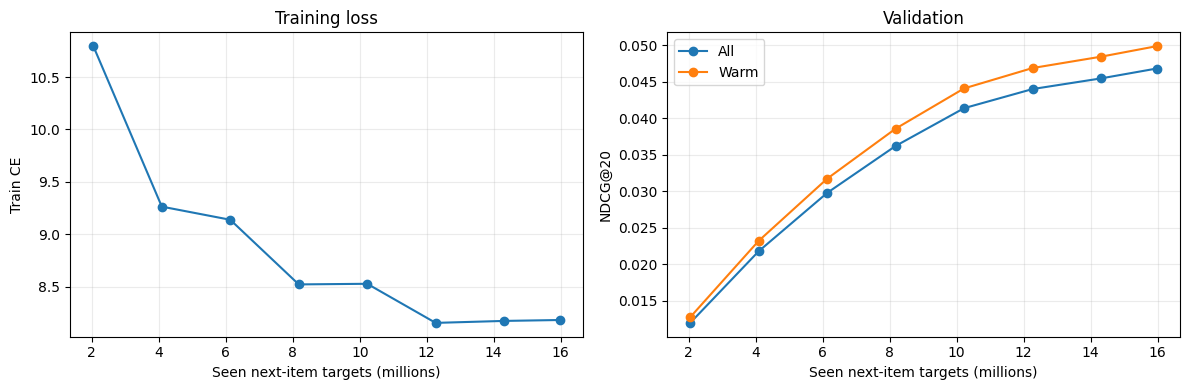

In [12]:
history_df = pd.DataFrame(history)
display(history_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df['seen_targets'] / 1e6, history_df['train_cross_entropy'], marker='o')
axes[0].set(xlabel='Seen next-item targets (millions)', ylabel='Train CE', title='Training loss')
axes[1].plot(history_df['seen_targets'] / 1e6, history_df['val_ndcg@20'], marker='o', label='All')
axes[1].plot(history_df['seen_targets'] / 1e6, history_df['val_warm_ndcg@20'], marker='o', label='Warm')
axes[1].set(xlabel='Seen next-item targets (millions)', ylabel='NDCG@20', title='Validation')
axes[1].legend()
for axis in axes:
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.show()